> **Archived (v1).** This is the original toy-data version of the notebook, kept for reference. It uses the archived `markovChain.py` in this folder. The current version lives in `notebooks/conflatedPlayPrediction.ipynb`.

# Conflated Play Prediction: Markov Chain + Classifier

Per Sections 4.2-4.3 of the Smart Stadium paper, play-type prediction combines two independent signals:

1. **Markov Chain (MC)** over play states `(down, play_type, field_position)`, capturing the "grammar" of play sequences (e.g. a Fake Punt is far more likely near midfield than on your own 10).
2. **A play-type classifier** (in the paper, a CNN over video clips) that predicts play type directly from a single play, with no sequence context.

These are **conflated** (entry-wise multiplication of the two probability vectors, then renormalized) rather than picking one or the other, because they make independent kinds of mistakes: the classifier can be fooled by a bad clip (e.g. an ad instead of the play), while the MC has no idea what's actually happening on the field. The paper's Figure 11 also uses a small trained network to learn per-class correction weights on top of the raw product.

There is **no LSTM** in this design -- the paper explicitly considered feeding the previous play into a Recurrent Neural Network as an alternative fusion strategy, but found conflation worked better and used that instead. This notebook implements the MC + conflation pipeline described in the paper, using `markovChain.py` and `conflation.py`.

**Placeholder note:** the real Markov Chain is meant to be trained on the CBS Sports NCAA play-by-play XML dataset described in Section 3.3, and the classifier probabilities are meant to come from the video pipeline (`playerDetection.py` / tactical map). Neither is available in this repo yet, so this notebook simulates both with a toy play-sequence generator and a noisy stand-in classifier, purely to demonstrate that the pipeline is wired correctly end to end. Swap `simulate_play_sequences` for a real XML parser and `simulate_classifier_output` for actual video-classifier probabilities when those are ready.

In [1]:
import sys, os
from pathlib import Path
# make the repo root importable whether Jupyter starts in the repo root or next to this notebook
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'conflation.py').exists())
sys.path.insert(0, str(ROOT))

import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

from archive.v1_markov_chain.markovChain import PlayMarkovChain  # archived v1, not the current markovChain.py
from conflation import conflate_probabilities, fit_conflation_weights

rng = np.random.default_rng(7)

## 1. Placeholder play-sequence data

Stands in for the CBS Sports XML dataset (Section 3.3). Generates games as sequences of `(down, play_type, field_bucket)` states, with toy tendencies (run-heavy early downs, pass on 3rd & long, punt/field-goal choice on 4th down) so the Markov Chain has real structure to learn -- not meant to be a realistic football simulator, just enough signal to exercise the pipeline.

The classifier in the paper predicts a 5-class subset of play types (`run, pass, field goal, punt, other`) -- kickoff and PAT are part of the full MC state space but aren't simulated here.

In [2]:
CLASSIFIER_PLAY_TYPES = ('R', 'P', 'F', 'U', 'O')  # run, pass, field goal, punt, other

def sample_play_type(down, bucket):
    if down == 4:
        probs = {'F': 0.7, 'U': 0.05, 'R': 0.1, 'P': 0.1, 'O': 0.05} if bucket >= 6 \
            else {'U': 0.75, 'F': 0.02, 'R': 0.1, 'P': 0.1, 'O': 0.03}
    elif down == 3:
        probs = {'P': 0.65, 'R': 0.25, 'F': 0.0, 'U': 0.0, 'O': 0.1}
    else:  # 1st/2nd down -- run-leaning in own territory, more balanced near midfield
        run_bias = 0.55 if bucket < 5 else 0.4
        probs = {'R': run_bias, 'P': 1 - run_bias - 0.05, 'F': 0.0, 'U': 0.0, 'O': 0.05}
    types, weights = zip(*probs.items())
    return rng.choice(types, p=np.array(weights) / sum(weights))


def advance_state(down, bucket, play_type):
    if play_type in ('F', 'U'):  # possession changes hands
        return 1, int(rng.integers(0, 10))
    gain = int(rng.integers(-1, 6)) if play_type == 'R' else int(rng.integers(-3, 12))
    new_bucket = min(9, max(0, bucket + gain))
    converted = gain >= 3 or down == 4
    return (1, new_bucket) if converted else (down + 1, new_bucket)


def simulate_play_sequences(n_games=150, plays_per_game=50):
    sequences = []
    for _ in range(n_games):
        down, bucket = 1, int(rng.integers(0, 10))
        seq = []
        for _ in range(plays_per_game):
            play_type = sample_play_type(down, bucket)
            seq.append((down, play_type, bucket))
            down, bucket = advance_state(down, bucket, play_type)
        sequences.append(seq)
    return sequences


sequences = simulate_play_sequences()
flat_plays = [play for seq in sequences for play in seq]
print(f'{len(sequences)} games, {len(flat_plays)} plays total')
print('play type distribution:', Counter(p[1] for p in flat_plays))

150 games, 7500 plays total
play type distribution: Counter({'P': 3956, 'R': 2842, 'O': 430, 'F': 208, 'U': 64})


## 2. Placeholder classifier output

Stands in for the video CNN's softmax output. Correlated with the true play type but noisy, since the point here is just to exercise the conflation logic, not to build a real classifier.

In [3]:
def simulate_classifier_output(true_type, confusion_strength=2.5):
    logits = rng.normal(0, 1, size=len(CLASSIFIER_PLAY_TYPES))
    logits[CLASSIFIER_PLAY_TYPES.index(true_type)] += confusion_strength
    exp = np.exp(logits - logits.max())
    return exp / exp.sum()

## 3. Fit the Markov Chain on a training split of games

In [4]:
train_seqs, test_seqs = sequences[:100], sequences[100:]

mc = PlayMarkovChain()
mc.fit(train_seqs)
print('transition matrix shape:', mc.transition_matrix.shape)

# example: what's the MC's prediction after a 1st-down run at the 50 (bucket 5)?
example_state = (1, 'R', 5)
example_proba = mc.next_play_type_proba(example_state, play_types=CLASSIFIER_PLAY_TYPES)
for play_type, p in zip(CLASSIFIER_PLAY_TYPES, example_proba):
    print(f'  P(next={play_type} | {example_state}) = {p:.3f}')

transition matrix shape: (280, 280)
  P(next=R | (1, 'R', 5)) = 0.182
  P(next=P | (1, 'R', 5)) = 0.677
  P(next=F | (1, 'R', 5)) = 0.002
  P(next=U | (1, 'R', 5)) = 0.002
  P(next=O | (1, 'R', 5)) = 0.137


## 4. Build evaluation samples and fit conflation weights

Each sample pairs the (simulated) classifier's output for a play with the MC's prediction from the *previous* play's state, plus the true label -- exactly the inputs `conflate_probabilities` fuses.

In [5]:
def build_eval_samples(seqs):
    samples = []
    for seq in seqs:
        for current, nxt in zip(seq, seq[1:]):
            true_type = nxt[1]
            if true_type not in CLASSIFIER_PLAY_TYPES:
                continue
            cnn_probs = simulate_classifier_output(true_type)
            mc_probs = mc.next_play_type_proba(current, play_types=CLASSIFIER_PLAY_TYPES)
            samples.append((cnn_probs, mc_probs, CLASSIFIER_PLAY_TYPES.index(true_type)))
    return samples

train_samples = build_eval_samples(train_seqs)
test_samples = build_eval_samples(test_seqs)
print(f'{len(train_samples)} train samples, {len(test_samples)} test samples')

weights = fit_conflation_weights(train_samples, len(CLASSIFIER_PLAY_TYPES), epochs=300, lr=0.5)
print('learned per-class weights:', dict(zip(CLASSIFIER_PLAY_TYPES, weights.round(3))))

4900 train samples, 2450 test samples
learned per-class weights: {'R': 0.892, 'P': 0.823, 'F': 0.926, 'U': 1.115, 'O': 1.319}


## 5. Compare accuracy: classifier alone vs. MC alone vs. conflated

Mirrors the paper's evaluation in Section 4.3 (Fig. 12), which found the conflated Neural Net + Markov Model reached 87.2% vs. 75.3% for the classifier alone.

classifier alone            : 0.885
MC alone                    : 0.505
conflated (unweighted)      : 0.921
conflated (learned weights) : 0.926


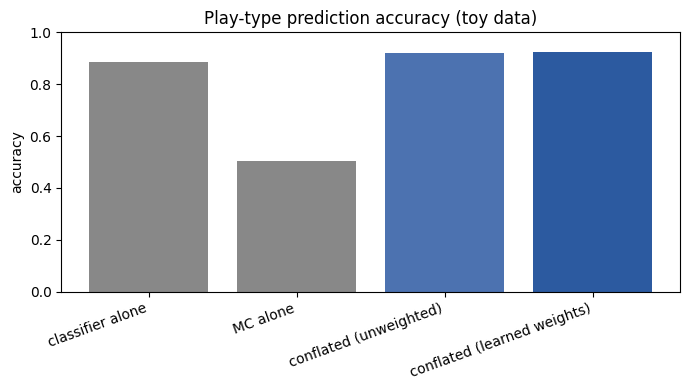

In [6]:
def accuracy(samples, predict_fn):
    correct = sum(1 for cnn_p, mc_p, label in samples if predict_fn(cnn_p, mc_p) == label)
    return correct / len(samples)

results = {
    'classifier alone': accuracy(test_samples, lambda c, m: np.argmax(c)),
    'MC alone': accuracy(test_samples, lambda c, m: np.argmax(m)),
    'conflated (unweighted)': accuracy(test_samples, lambda c, m: np.argmax(conflate_probabilities([c, m]))),
    'conflated (learned weights)': accuracy(
        test_samples, lambda c, m: np.argmax(conflate_probabilities([c, m], class_weights=weights))
    ),
}
for name, acc in results.items():
    print(f'{name:28s}: {acc:.3f}')

plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values(), color=['#888', '#888', '#4c72b0', '#2c5aa0'])
plt.ylabel('accuracy')
plt.title('Play-type prediction accuracy (toy data)')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()